# Flux-pumped λ/4 CPW JPA (QPDK `cpw_jpa`), rebuilt in the Quantcore PDK

**What it is.** A Josephson parametric amplifier used in reflection: a λ/4 CPW resonator whose open end couples
through a capacitor to the signal line and whose far end is shorted to ground through a DC SQUID. The SQUID's
inductance L_s(Φ) = Φ0 / (2π I_c |cos πΦ/Φ0|) tunes the resonance; a shorted pump line next to the SQUID loop
modulates Φ at twice the signal frequency (three-wave mixing) and amplifies (Yamamoto et al., APL 93, 042510 (2008);
the WMI devices of Pogorzalek et al., PR Applied 8, 024012 (2017)).

**Source.** QPDK (gdsfactory/quantum-rf-pdk, MIT): `qpdk/cells/parametric_amplifier.py` (`cpw_jpa`,
`squid_termination`), `qpdk/samples/cpw_jpa_chip.py` and the notebook `vacask_cpw_parametric_amplifier`; cloned
read-only into `build/external/quantum-rf-pdk` (rev e9be61f). QPDK was read, never imported or run.

**This is a Quantcore-PDK rebuild**: our die frame, sapphire, Nb film (with its kinetic inductance), the Nb trilayer
SQUID, our cells and routes, our LOM.

| | QPDK source | Quantcore rebuild (why) |
|---|---|---|
| resonator | 4680 µm λ/4 meander, 10/6 µm CPW, 6 meanders (incl. a 10 µm termination lead) | the same length: qcc meander route + `SquidTermination` lead and landing head |
| coupling | interdigital capacitor, 8 fingers × 50 µm, 2 µm gap, 5 µm fingers (≈ 28 fF) | KQC `FingerCapacitorSquare` with the same fingers (LOM: Igreja–Dias) |
| SQUID | I_c,tot 4.8 µA (L_s(0) = 68.6 pH), loop on the ground side of an etched pocket | **largest PDK trilayer SQUID** (two 2 × 2 µm junctions, I_c,tot ≈ 1.3 µA, L_s(0) ≈ 0.25 nH): the PDK junction rule (J_c 0.16 µA/µm², fingers ≤ 2 µm) cannot reach 4.8 µA; flagged `pdk_rn`, and both values are simulated |
| pump | shorted CPW 200 µm, 2 µm ground strip, short 20 µm past the SQUID | the same, drawn by `SquidTermination` |
| chip | launchers on signal and pump (`cpw_jpa_chip`) | 7.5 × 7.5 mm PDK die, Quantcore `BondPad`s 100 µm from the edge |
| substrate / film | QPDK stack (Si, Al) | sapphire 650 µm, εr 10.25; Nb 200 nm, L_s 0.116 pH/□ |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far — the 7.5 mm die, the signal and pump bond pads, the signal feed with its
coupling capacitor, the SQUID termination (the nonlinear element), the λ/4 resonator and the pump line, and then the
whole chip (the target, the sim groups, the save). Then the same steps as the Flow strip of the Quantcore KLayout
plugin: **Check** (DRC, netlist) → **LOM** (the amplifier's circuit models, their plots, one change by hand) →
**Simulate** (export to HFSS, the Q3D C-matrices of the JPA and of the termination, the eigenmode simulation with the
SQUID as a lumped inductor, the full-wave run on the eigenmode's mesh settings) → **Results** (the eigenmodes plotted,
f0 and κ read off, FEM against the LOM, a feedback step and the iteration to the design's own target, 6.07 GHz) →
**Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in four cells, with its outputs) is kept as `qpdk_cpw_jpa.v1.ipynb`; both save the same
`qpdk_cpw_jpa.json`.

## Setup

The imports, the output folder and the switches. `_amplifiers` holds the amplifier notebooks' helpers (the PDK
facts, value tables, plots, the linear S-parameters of a LOM netlist, and the readers that put kept FEM results in
amplifier terms); `_common` the helpers all design notebooks share (tables, snapshots, the PDK placement, the FEM and
feedback steps). The physics is `quantcore_circuits.analysis.amplifiers`, the cells
`quantcore_circuits.layouts.others.amplifiers`.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
import os, sys
from pathlib import Path
import numpy as np
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "amplifiers"))
from _common import *                            # netlist tables, simulate_groups, export_sims, snapshots, PDK helpers
from _amplifiers import pdk_facts_md, plot, show_md, table_md, lom_values, c_fF
from _amplifiers import jpa_mode, reflection_values   # v2: kept FEM results in amplifier terms (Results)
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk
from quantcore_circuits.analysis import amplifiers as amp
from quantcore_circuits.analysis.synthesis import cpw_properties
from quantcore_circuits.layouts.others.amplifiers import SquidTermination
from quantcore_circuits.circuit.bridges import junction_from_fingers, rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/amplifiers")
PDK = get_pdk()

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the film's kinetic inductance, the cheese and the 3/0
keep-outs. For this chip that means: the 7.5 mm die with the QCT frame, the two bond pads 100 µm from the west and
east edges, the Nb film's kinetic inductance in the CPW's Z0 and v_p, and the largest SQUID the PDK finger range
allows (two 2 × 2 µm trilayer junctions): an amplifier SQUID is far outside the qubit R_n window (flagged `pdk_rn`,
not retuned), and it cannot reach the source's 4.8 µA.

In [4]:
show_md(pdk_facts_md(PDK))

| PDK | value |
|---|---|
| substrate | sapphire 650 µm, εr 10.25 |
| film | Nb 200 nm, λ_L 90 nm → L_s 0.116 pH/□ (kinetic, in every CPW / wire formula) |
| junction rule | Nb/AlOx/Nb trilayer, Δ 1.4 meV, J_c 0.163 µA/µm², R_n window 40–50 kΩ, fingers 0.1–2 µm |
| frame | die 7.5 × 7.5 mm standard, margin 100 µm, marker areas 500 µm, brand QCT |
| pad rule | outer etch 100 µm (one dicing-marker width) from the die edge (`edge="auto"`) |
| cheese | PDK band 3 rows of 5 µm squares, 20 µm gap, around the 3/0 keep-outs (unless the original has its own) |
| 3/0 keep-out | routes + 10 µm, components + 24 µm |

# Design: the layout, one segment at a time

An amplifier chip is laid out the way a designer would do it by hand: the die, the bond pads, the feed (and pump)
line, the nonlinear element, the routing, and then the whole chip. Each segment is one cell with one picture of the
chip so far (and, live, KLayout redraws after every cell). A route always joins two ports, so a line is drawn once
both of its ends exist. The line under each picture counts what is on the chip; it says 0 qubits: an amplifier has
none, its junctions sit inside the amplifier cell (counted among the other components).

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm die with the QCT frame |
| 2 | the signal `BondPad` (west) and the pump `BondPad` (east, 400 µm below the signal axis) |
| 3 | the signal feed: the QPDK coupling capacitor `CC` and the 50 Ω line `L_SIG` from the signal pad to it |
| 4 | the nonlinear element: the PDK SQUID (drawn against the source's), then the `SquidTermination` `ST` |
| 5 | the routing: the λ/4 resonator `JPA` (a fixed-length meander, capacitor → termination) and the pump line `L_PUMP` |
| 6 | the whole chip: the design's target, the sim groups, the save |

## Design 1 · The die and its frame
A standard 7.5 × 7.5 mm Quantcore die: dicing L-markers, corner marker areas, the 100 µm design margin and the
device ID are drawn by the chip frame. `YC` is the die's mid-height: the signal axis.

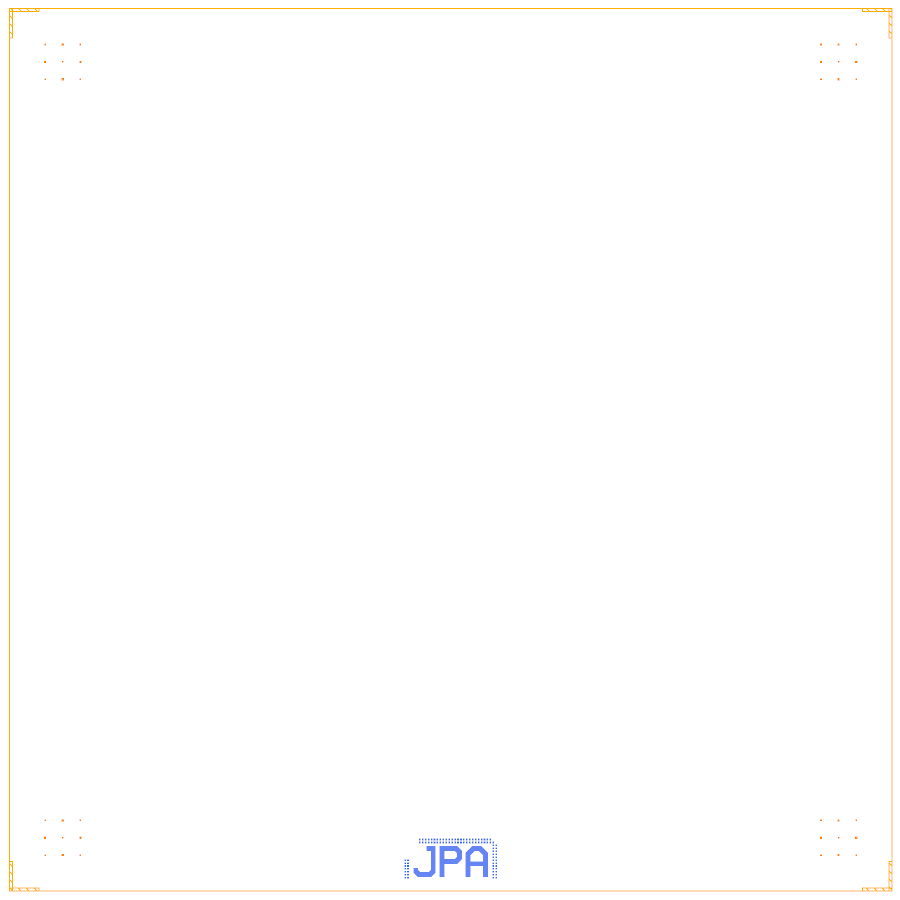

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/qpdk_cpw_jpa_s1_die.png')

In [5]:
W = H = 7500
YC = 3750
d = Designer("qpdk_cpw_jpa", box=(0, 0, W, H), chip={"name_chip": "JPA"}, live=LIVE)
layout_step(d, OUT / "qpdk_cpw_jpa_s1_die.png", size=(900, 900), width=400)

## Design 2 · Bond pads (the 100 µm rule)
Two Quantcore `BondPad`s: the signal pad on the west edge and the pump pad on the east edge. `edge="auto"` slides each
pad perpendicular to its die edge until its outer etch is the PDK `pad_edge` (100 µm) from it. The pump pad sits 400
µm below the signal axis, where the pump line from the termination arrives (Design 5). `X_CC` and `X_ST`, the
capacitor's and the termination's x, are set here too: the 650 µm between them is the straight the resonator meanders
on.

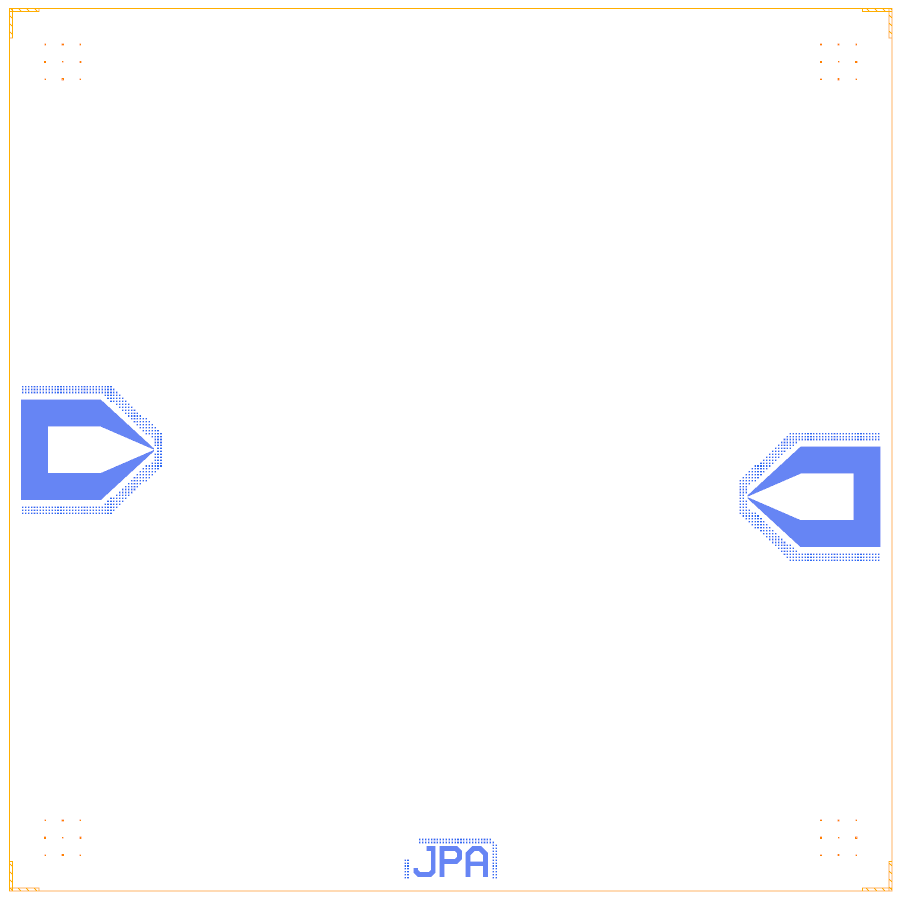

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `P_SIG`, `P_PUMP`.

WindowsPath('examples/designs/amplifiers/qpdk_cpw_jpa_s2_pads.png')

In [6]:
X_CC, X_ST = 3250, 3900                          # capacitor centre, SQUID termination (lead start): a compact
                                                 # 6-meander resonator between them, as QPDK draws it
with d.batch():
    d.add("P_SIG", "BondPad", at=(400, YC), rot=-90, edge="auto")
    d.add("P_PUMP", "BondPad", at=(7100, YC - 400), rot=90, edge="auto")
layout_step(d, OUT / "qpdk_cpw_jpa_s2_pads.png", size=(900, 900), width=400)

## Design 3 · The signal feed: the coupling capacitor and its line

The JPA is used in reflection: the signal comes in from `P_SIG`, meets the resonator through the coupling capacitor
and leaves the same way. `CC` is KQC's `FingerCapacitorSquare` with QPDK's coupling capacitor's fingers (8 fingers
× 50 µm, 5 µm wide, 2 µm gaps; ≈ 28 fF in QPDK); `L_SIG` is the plain 50 Ω feed from the pad to its port `a`. Both
need nothing else on the chip, so they come before the nonlinear element. The pump has its own line (Design 5).

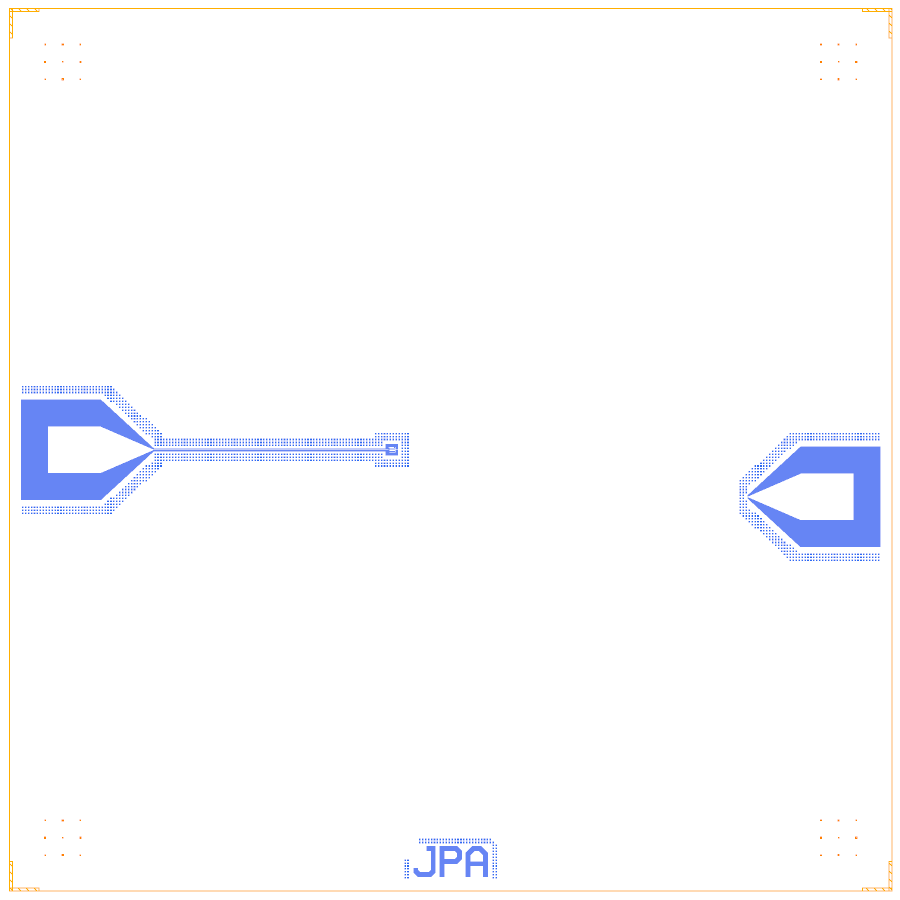

**On the chip so far:** 2 pads · 0 qubits · 1 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `CC` and 1 route(s) `L_SIG`.

WindowsPath('examples/designs/amplifiers/qpdk_cpw_jpa_s3_feed.png')

In [7]:
with d.batch():
    cc = d.add("CC", "FingerCapacitorSquare", at=(X_CC, YC), finger_number=8, finger_length=50, finger_width=5,
               finger_gap=2)
    d.route("L_SIG", "P_SIG.a", "CC.a")
layout_step(d, OUT / "qpdk_cpw_jpa_s3_feed.png", size=(900, 900), width=400)

## Design 4 · The nonlinear element: the SQUID termination

**The SQUID.** The source's SQUID (I_c,tot 4.8 µA, L_s(0) 68.6 pH) is beyond the PDK rule (J_c 0.16 µA/µm², fingers ≤
2 µm): the largest the PDK allows is two 2 × 2 µm trilayer junctions (`BIG_JJ`). `SquidTermination.qcc_squid` gives
the drawn SQUID's L_s(0) and C_J from the PDK; the table puts it next to the source's. `JUNCTION` (its L_s and C_J)
goes on the instance: the LOM uses it, the DRC flags its `pdk_rn`, the eigenmode job draws it as a lumped inductor.

**The termination.**
Quantcore `SquidTermination`: the lead (10 µm) ends on a 6 × 28 µm landing head in a 34 µm pocket; the
trilayer SQUID bridges the 20 µm junction gap to ground (its two straight fingers sit ±8 µm off-axis, on the
head); the pump CPW runs past the ground side, shorted 20 µm beyond the SQUID axis. Ports: `a` (resonator side),
`pump`; `squid_a` / `squid_b` mark the junction ends for FEM.

The first picture is the chip so far, the second zooms on the termination (the pocket, the landing head, the SQUID's
fingers, the pump line and its 2 µm ground strip).

In [8]:
BIG_JJ = {"finger_width": 2.0, "second_finger_width": 2.0}   # the largest junction the PDK finger range allows
SQ = SquidTermination.qcc_squid({"junction_params": BIG_JJ})
jv = junction_from_fingers(2.0, 2.0, n=2, pdk=PDK)
LS_SRC = amp.lj_from_ic(4.8e-6) * 1e9                         # nH, QPDK I_c,tot = 4.8 µA
show_md(table_md(["SQUID", "I_c,tot (µA)", "L_s(0) (nH)", "C_J (fF)", "device R_n (kΩ)"], [
    ["drawn: 2 × trilayer 2.0 × 2.0 µm", 2 * jv.ic_each_nA / 1e3, SQ["Ls0_nH"], SQ["Cj_fF"], jv.rn_kohm],
    ["QPDK source", 4.8, LS_SRC, None, rn_from_lj(LS_SRC) / 1e3],
]))
JUNCTION = {"Lj_nH": SQ["Ls0_nH"], "Cj_fF": SQ["Cj_fF"]}      # on the instance: the LOM uses it, DRC flags pdk_rn

| SQUID | I_c,tot (µA) | L_s(0) (nH) | C_J (fF) | device R_n (kΩ) |
|---|---|---|---|---|
| drawn: 2 × trilayer 2.0 × 2.0 µm | 1.303 | 0.2525 | 400 | 1.688 |
| QPDK source | 4.8 | 0.06856 | – | 0.4581 |

{'pump': (49.0, -180.0, -90.0), 'a': (0.0, 0.0, 180.0), 'squid_a': (16.0, 0.0, None), 'squid_b': (36.0, 0.0, None)}


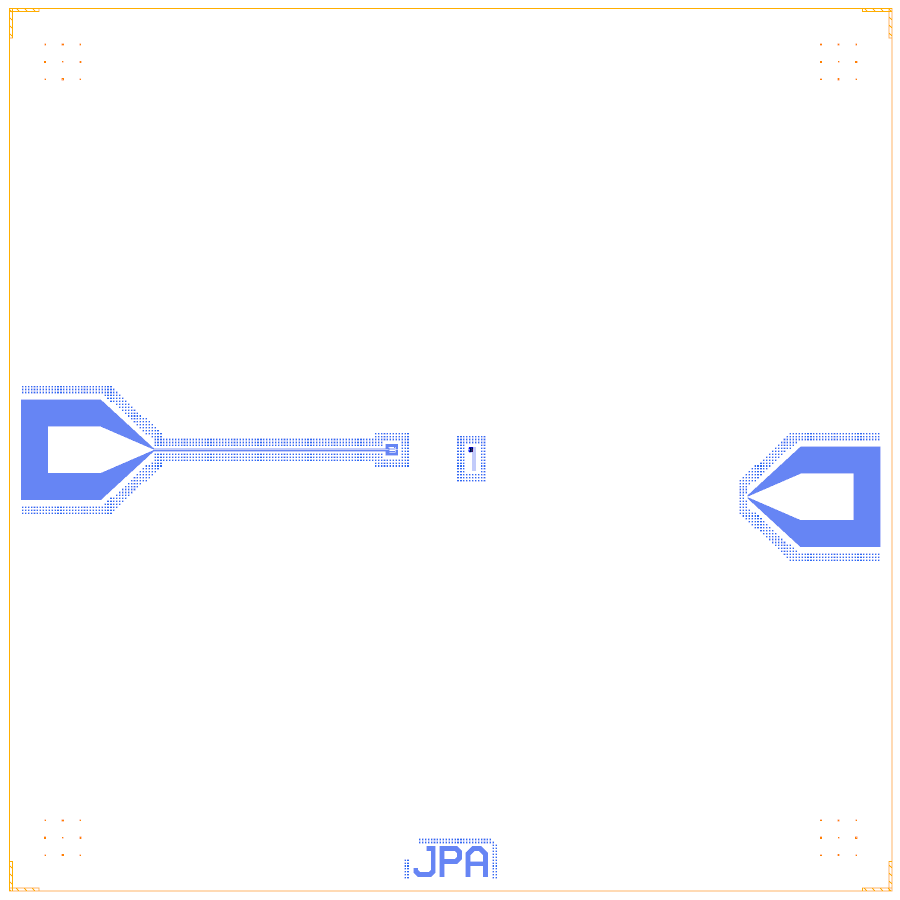

**On the chip so far:** 2 pads · 0 qubits · 2 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `ST`.

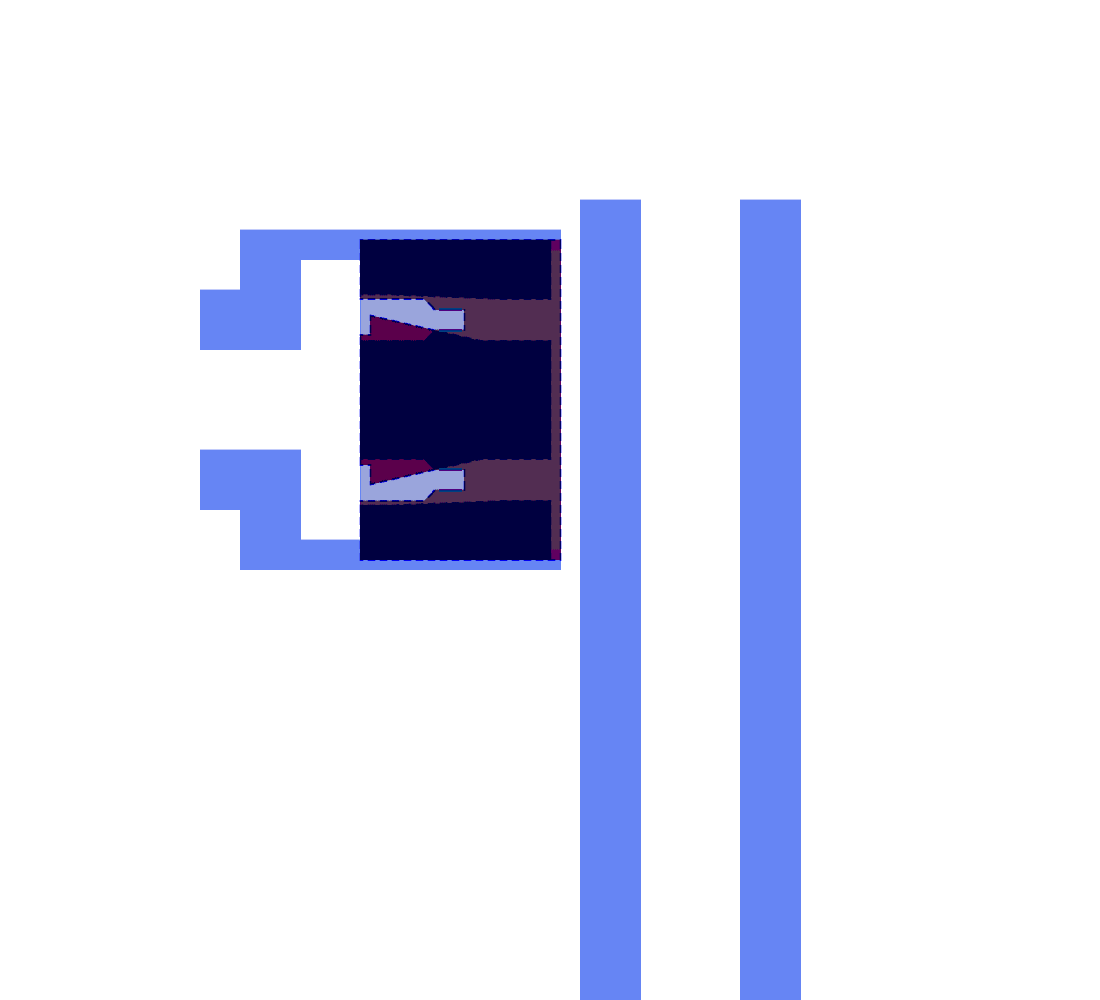

WindowsPath('examples/designs/amplifiers/qpdk_cpw_jpa_s4_termination.png')

In [9]:
with d.batch():
    st = d.add("ST", "SquidTermination", at=(X_ST, YC), junction=JUNCTION, junction_params=BIG_JJ)
print({p: (round(v.pos.x, 1), round(v.pos.y, 1), v.angle) for p, v in st.ports.items()})
layout_step(d, OUT / "qpdk_cpw_jpa_s4_squid.png", size=(900, 900), width=400)
xa, ya = port_xy(d, "ST.a")                      # the termination's lead end (the resonator side)
snap(d, OUT / "qpdk_cpw_jpa_s4_termination.png", box=(xa - 20, ya - 60, xa + 90, ya + 40), size=(1100, 1000),
     width=440)

## Design 5 · Routing: the λ/4 resonator and the pump line
* `JPA`: the λ/4 resonator, a fixed-length meander from the capacitor to the termination. QPDK's 4680 µm include
  the 10 µm termination lead; ours has a 10 µm lead and a 6 µm head, so the route is 4680 − 16 = 4664 µm.
* `L_PUMP`: the pump line from the termination's pump port (facing south) to the east pad.

`meanders=6` keeps QPDK's six meander sections. Six turns need 2·r·(6 + 1) µm of straight between the capacitor and
the termination (478 µm here), so the bend radius is 30 µm; with a larger `r` the router lays fewer, taller turns
(same length) and warns. The leftover length (4664 µm minus the straight path) goes into that one KQC `Meander`;
Design 6 prints the built lengths (from the v1 run: `JPA` 4664.0 µm).

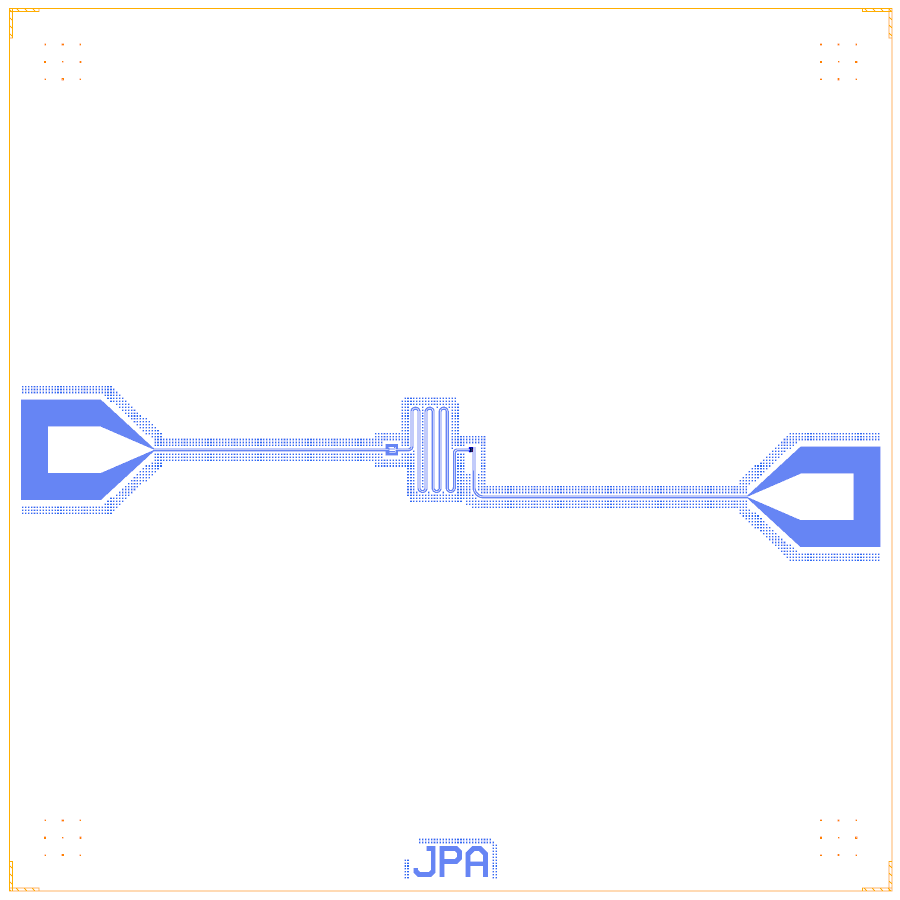

**On the chip so far:** 2 pads · 0 qubits · 2 other components · 3 routes · 0 declared couplings. **This step added** 2 route(s) `JPA`, `L_PUMP`.

WindowsPath('examples/designs/amplifiers/qpdk_cpw_jpa_s5_resonator_pump.png')

In [10]:
L_RES = 4680.0
with d.batch():
    d.route("JPA", "CC.b", "ST.a", meander=L_RES - 16.0, r=30).set(meanders=6)
    xp, yp = port_xy(d, "ST.pump")
    d.route("L_PUMP", "ST.pump", "P_PUMP.a", nodes=[(xp, YC - 400)], r=80)
layout_step(d, OUT / "qpdk_cpw_jpa_s5_resonator_pump.png", size=(900, 900), width=400)

## Design 6 · The whole chip: the target, the sim groups, the save

**Target.** `d.targets(JPA=…)` keeps the design's own aim with it: QPDK's resonance at Φ = 0, 6.07 GHz (on QPDK's
stack and SQUID). Results 4–5 feed back towards it.

**Sim groups.** `jpa`: the capacitor, the resonator and the termination with a 150 µm margin, for a Q3D C-matrix and
an eigenmode job; `termination`: the termination alone (80 µm), Q3D. The lines leaving a box (the feed, the pump line)
are cut there.

**No centring.** The pump pad sits 400 µm below the signal axis, so the content is off-centre in y; the v1 leaves it
there (Check 1's `pdk_report` measures it).

**Save.** `save_design` writes `qpdk_cpw_jpa.json` and compares it with the file it replaces (the previous run's, e.g.
the `.v1` notebook's): it should say *same design*. The route lengths are the built ones; the picture is the whole
chip.

**Same design as before:** `examples/designs/amplifiers/qpdk_cpw_jpa.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer qpdk_cpw_jpa: 4 instances, 3 routes, live=False> → examples\designs\amplifiers\qpdk_cpw_jpa.json
{'L_SIG': 1973.5, 'JPA': 4664.0, 'L_PUMP': 2511.7}


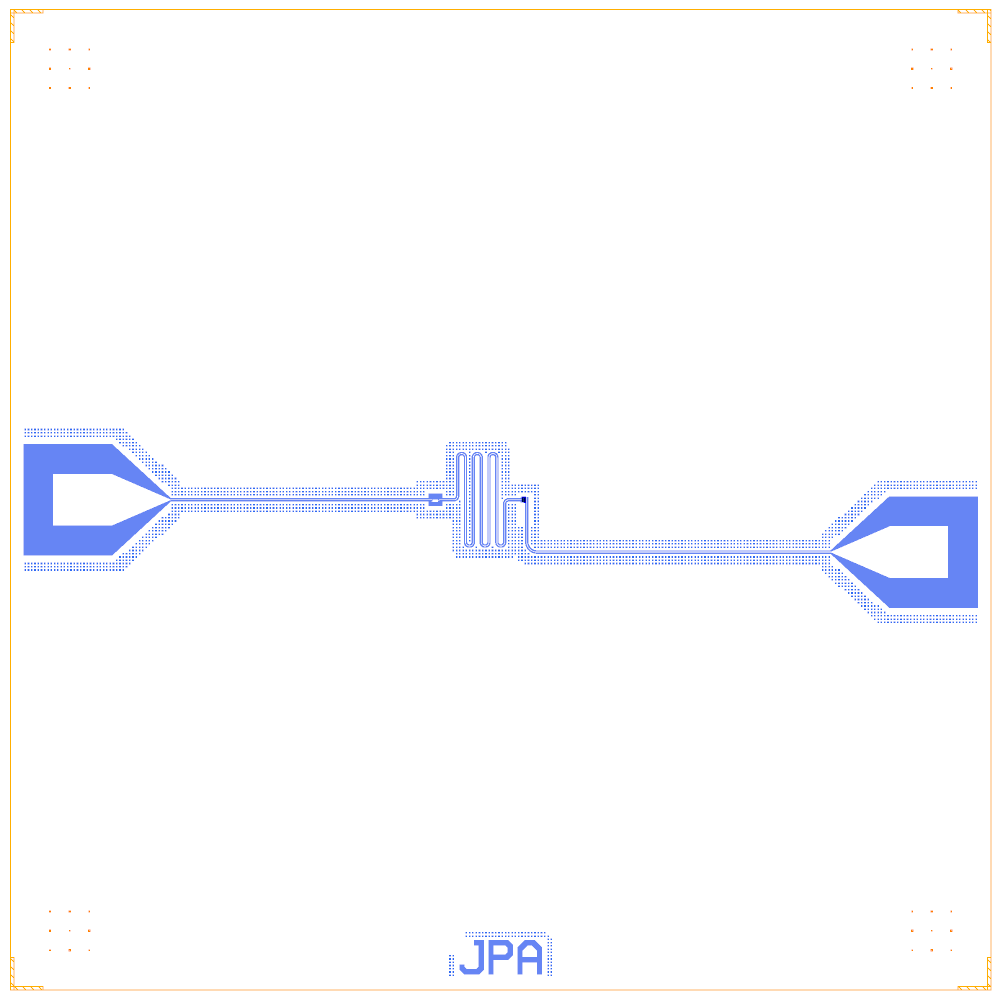

**On the chip so far:** 2 pads · 0 qubits · 2 other components · 3 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/designs/amplifiers/qpdk_cpw_jpa_s6_chip.png')

In [11]:
d.targets(JPA={"f_GHz": 6.07})                    # QPDK SAX resonance at Φ = 0 (its stack, its SQUID)
d.sim_group("jpa", ["CC", "JPA", "ST"], margin_um=150, analyses=["q3d_cmatrix", "eigenmode_epr"])
d.sim_group("termination", ["ST"], margin_um=80, analyses=["q3d_cmatrix"])
if not LIVE:
    d.show()
DESIGN, same = save_design(d, OUT / "qpdk_cpw_jpa.json")
display(Markdown(same))
print(d, "→", DESIGN)
print({k: round(v, 1) for k, v in d.result.route_lengths().items()})
layout_step(d, OUT / "qpdk_cpw_jpa_s6_chip.png", size=(1000, 1000), width=480)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
Errors would block fab; warnings are layout hints (`dangling_port` on `squid_a` / `squid_b`: junction attachment
points, not route ends). **PDK design warnings** are flagged, never enforced: `pdk_rn` — the SQUID's device
R_n (≈ 1.7 kΩ) is far below the qubit window 40–50 kΩ, as an amplifier junction must be.

Expected here (from the v1 run): no errors, two `dangling_port` warnings (`ST.squid_a`, `ST.squid_b`) and `pdk_rn` on
`ST` (L_J 0.2525 nH); content centre − die centre (+0, −200) µm.

`pdk_report(d)` sums up the PDK side.

In [ ]:
print(d.drc())
show_md(pdk_report(d))

## Check 2 · Netlist
The builder joins `L_SIG` (a wire: pad → capacitor), the `FingerCapacitorSquare` π network, and one λ/4 `TLres`
made of the `JPA` route plus the termination's lead. `SquidTermination`'s LOM puts the SQUID in as the line's
shorted end at its **inductive equivalent length** ℓ_eq = lead + head + L_s/L' (L' of the 10/6 µm CPW with the Nb
kinetic inductance), so f_r ≈ f_λ/4 / (1 + L_s / L'ℓ). The pump line is a control (flux), no circuit element.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The circuit models

Four views of the same JPA: (a) QuCat's normal mode of the lumped circuit, (b) the exact distributed model of the
SQUID-terminated λ/4, (c) its flux tuning, (d) the flux-pumped gain. Their plots are in LOM 2.

**(a) QuCat normal modes** of the selection pad + feed + capacitor + resonator: the JPA mode's frequency and its
external linewidth through the 50 Ω pad.

In [ ]:
res = simulate_groups(d, {"JPA": ["P_SIG", "L_SIG", "CC", "JPA", "ST"]}, max_modes=1)
display(Markdown(modes_md(res["JPA"])))

**(b) The distributed model** (`analysis.amplifiers.cpw_jpa_s11`): port — C_c — λ/4 CPW (Z0, v_p with kinetic
inductance) — L_s(Φ) to ground, the exact transmission-line formula; f0 at the steepest reflection phase,
κ/2π = 4 / max|dφ/df|. Drawn PDK SQUID next to the QPDK source SQUID (same layout, same C_c).

In [ ]:
cpw = cpw_properties(6.5, 10, 6, PDK.name)
caps = {n: c_fF(v) for n, v in lom_values(lb, "C").items() if "CC" in n}
CC_FF = max(caps.values())                       # the series (mutual) capacitance of the finger capacitor
LENGTH = d.result.route_lengths()["JPA"] + 16.0  # route + termination lead and head
f = np.linspace(4.0e9, 7.5e9, 350001)

def jpa(ls_nH, cc_fF=CC_FF, length=LENGTH):
    return amp.resonance(f, amp.cpw_jpa_s11(f, cc_fF * 1e-15, cpw["Z0_ohm"], cpw["vp_m_s"], length, ls_nH * 1e-9))

rows = []
for label, ls in (("drawn PDK SQUID", SQ["Ls0_nH"]), ("QPDK source SQUID", LS_SRC), ("no SQUID (bare λ/4)", 0.0)):
    f0, k = jpa(ls)
    rows.append([label, ls, f0 / 1e9, k / 1e6, f0 / k])
show_md(f"Z0 {cpw['Z0_ohm']:.1f} Ω, v_p {cpw['vp_m_s']:.3e} m/s (α_k {cpw['alpha_k']:.1%}), C_c {CC_FF:.1f} fF "
        f"(LOM), ℓ {LENGTH:.0f} µm\n\n" + table_md(["SQUID", "L_s(0) (nH)", "f0 (GHz)", "κ/2π (MHz)", "Q_ext"], rows))

**(c) Flux tuning** f0(Φ) for both SQUIDs, and the operating point Φ = 0.3 Φ0 that QPDK uses for the gain.

In [ ]:
phis = np.linspace(0, 0.45, 19)
curves = {lab: [jpa(float(amp.squid_ls(ls, p)))[0] / 1e9 for p in phis]
          for lab, ls in (("drawn PDK SQUID", SQ["Ls0_nH"]), ("QPDK source SQUID", LS_SRC))}
OP = {}
for lab, ls in (("drawn PDK SQUID", SQ["Ls0_nH"]), ("QPDK source SQUID", LS_SRC)):
    fa, k = jpa(float(amp.squid_ls(ls, 0.3)))
    fb, _ = jpa(float(amp.squid_ls(ls, 0.301)))
    OP[lab] = {"f0": fa, "kappa": k, "df_dphi": (fb - fa) / 1e-3}
show_md(table_md(["SQUID", "f0 at 0.3 Φ0 (GHz)", "κ/2π (MHz)", "df0/dΦ (GHz/Φ0)", "threshold Φ_p (mΦ0)"],
                 [[k, v["f0"] / 1e9, v["kappa"] / 1e6, v["df_dphi"] / 1e9, 1e3 * v["kappa"] / abs(v["df_dphi"])]
                  for k, v in OP.items()]))

**(d) Gain vs pump** (single-mode flux-pumped paramp, `analysis.amplifiers.flux_pumped_gain`): pump at 2 f0, a
modulation δω = 2π |df0/dΦ| Φ_p; r = δω/κ; peak gain ((1 + r²)/(1 − r²))², threshold r = 1. QPDK's harmonic
balance gives somewhat less (the line's higher modes take part); this is the single-mode bound.

In [ ]:
op = OP["drawn PDK SQUID"]
det = np.linspace(-3, 3, 601) * op["kappa"]
show_md(table_md(["r", "peak gain (dB)", "pump flux Φ_p (mΦ0)", "−3 dB bandwidth (MHz)"], [
    [r, float(amp.db(amp.flux_pumped_peak_gain(r))), 1e3 * r * op["kappa"] / abs(op["df_dphi"]),
     float(np.ptp(det[amp.db(amp.flux_pumped_gain(det, op["kappa"], r)) >= amp.db(amp.flux_pumped_peak_gain(r)) - 3]))
     / 1e6] for r in (0.5, 0.7, 0.8, 0.9)]))

## LOM 2 · The models in plots

Two plots: f0 against the static flux for the drawn PDK SQUID and the source's (model (c)), the operating point
Φ = 0.3 Φ0 marked; the phase-preserving gain of the drawn JPA at that point for four pump strengths r (model (d)).

In [ ]:
plot(OUT / "qpdk_cpw_jpa_tuning.png", [(phis, v, k) for k, v in curves.items()], "flux bias Φ (Φ0)",
     "f0 (GHz)", "SQUID-terminated λ/4: resonance vs flux (distributed model)", vline=0.3)
plot(OUT / "qpdk_cpw_jpa_gain.png",
     [(det / 1e6, amp.db(amp.flux_pumped_gain(det, op["kappa"], r)), f"r = {r}") for r in (0.5, 0.7, 0.8, 0.9)],
     "signal detuning from f_p/2 (MHz)", "gain (dB)", "drawn PDK SQUID at Φ = 0.3 Φ0: phase-preserving gain");

## LOM 3 · One change by hand: a smaller SQUID
Before the FEM, a design step by hand. One property: the SQUID's finger width 2.0 → 1.2 µm (junction area ÷ 2.8, L_s ×
2.8). Re-run the LOM and the distributed model: the participation L_s / (L_s + L'ℓ) grows, f0 drops, the flux tuning
steepens. The change is made on a copy (`design_copy`: a non-live Designer that never writes over the design file), so
the chip saved in Design 6 stays as it is and nothing is saved again. From the v1 run: L_s(0) 0.25 → 0.70 nH, the
LOM's f0 5.74 → 4.83 GHz.

In [ ]:
before = (res["JPA"].modes[0].f_GHz, *jpa(SQ["Ls0_nH"]))
SMALL = {"finger_width": 1.2, "second_finger_width": 1.2}
sq2 = SquidTermination.qcc_squid({"junction_params": SMALL})
d2 = design_copy(DESIGN)                         # a non-live copy of the saved design (never saved over it)
d2["ST"].set(junction_params=SMALL, junction={"Lj_nH": sq2["Ls0_nH"], "Cj_fF": sq2["Cj_fF"]})
res2 = simulate_groups(d2, {"JPA": ["P_SIG", "L_SIG", "CC", "JPA", "ST"]}, max_modes=1)
after = (res2["JPA"].modes[0].f_GHz, *jpa(sq2["Ls0_nH"]))
show_md(table_md(["SQUID fingers", "L_s(0) (nH)", "LOM f (GHz)", "distributed f0 (GHz)", "κ/2π (MHz)"], [
    ["2.0 × 2.0 µm", SQ["Ls0_nH"], before[0], before[1] / 1e9, before[2] / 1e6],
    ["1.2 × 1.2 µm", sq2["Ls0_nH"], after[0], after[1] / 1e9, after[2] / 1e6]]))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/amplifiers/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS
A Q3D C-matrix job of capacitor + resonator + termination (replaces the capacitor's estimate) and of the
termination alone (the SQUID pocket and pump strip), and an eigenmode job of the resonator with the SQUID as a
lumped inductor at `squid_a` / `squid_b` (L_J from the instance's junction: the SQUID's L_s at Φ = 0).
The pump-to-loop mutual inductance M needs a driven / magnetostatic run (not exported here; QPDK leaves it to EM).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/amplifiers/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["jpa", "termination"])
jobs_eig = export_sims(DESIGN, ["jpa"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

The capacitances of `jpa` (the finger capacitor's two sides — `CC.b` carries the resonator line — and the SQUID's
landing head; from the v1 run's job table the nets are `ST.island`, `CC.b` and `L_SIG`) and of `termination` (the head
in its pocket). Each net is named after its LOM node, so the matrix goes straight into the circuit (Results 3).
`fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `jpa` box in HFSS eigenmode: the SQUID is a lumped inductor between `squid_a` and `squid_b` with its L_s at Φ = 0
(0.2525 nH, the instance's junction), and the signal and pump lines leaving the box end in 50 Ω, so the JPA mode's Q
gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) adds the SQUID's energy
participation p_J and the mode's self-Kerr.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives the S-parameters of the same box. The library cannot hand the solved eigenmode **mesh** itself
to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group
and box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's mode nearest the LOM's f0 (the
LOM's f0 itself before the eigenmode is solved) and a fast sweep from 0.4 GHz below to 0.2 GHz above it.

A JPA is read in **reflection**: the resonance is in the phase of S11 at the signal port, not a notch in S21 (the fit
`driven_md` lists is made for hangers, so it may find none). Results 2 reads f0 and κ off S11 with
`reflection_values` (`analysis.amplifiers.resonance`: the steepest phase) from the Touchstone file the solve leaves
in the job folder; the kept copy in `fem/` holds `results.json` only and the next export empties the job folder, so
S11 is read in the run that solved it.

In [ ]:
f_jpa = res["JPA"].modes[0].f_GHz                # the LOM's f0 (LOM 1 a)
jobs_drv = driven_from_eigenmode(DESIGN, "jpa", jobs_eig["jpa"][0], keep_eig["jpa"], f_guess=f_jpa)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["jpa"]:
    display(Markdown(driven_md(keep_drv["jpa"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J, with the LOM's f0 as a dashed line. The JPA mode is the one near it
with the SQUID's participation (small: the SQUID is only the short of a λ/4 line). The table lists the modes and the
pyEPR values.

In [ ]:
plot_eigenmodes(keep_eig, OUT / "qpdk_cpw_jpa_eigenmodes.png", lom={"JPA": f_jpa})
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The JPA mode in the LOM's terms: `jpa_mode` takes the solved mode nearest the LOM's f0 with Q > 10 (a JPA is strongly
coupled), κ = f / Q_ext (the lines leaving the box are the only loss once pyEPR's dielectric Q is removed), p_J and
the self-Kerr from pyEPR. The driven run adds f0 and κ from the phase of S11 at the signal port (`reflection_values`),
when its trace is in the job folder (the run that solved it).

In [ ]:
fem_jpa = jpa_mode(keep_eig["jpa"], f_jpa)       # the eigenmode nearest the LOM's f0; {} without results
refl = reflection_values("L_SIG", keep_drv["jpa"], jobs_drv["jpa"][0])   # S11 at the signal port; {} without a trace
if fem_jpa:
    show_md(table_md(["JPA mode (eigenmode)", "value"], [[key, val] for key, val in fem_jpa.items()]))
if refl:
    show_md(f"Driven S11 at `L_SIG`: f0 {refl['f_GHz']:.4f} GHz, κ/2π {refl['kappa_MHz']:.2f} MHz (`{refl['file']}`)")
if not fem_jpa:
    print("No eigenmode results yet (RUN_FEM = True): this table would list the JPA mode's f, Q, κ = f/Q_ext, p_J and "
          "the self-Kerr (pyEPR); the driven run adds f0 and κ from S11.")
elif keep_drv["jpa"] and not refl:
    print("Driven results kept, but no S11 trace in the job folder (only results.json is kept): f0 and κ from the "
          "eigenmode above.")

## Results 3 · FEM against the LOM

Three comparisons. **LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates of the `jpa` components by
the C-matrix (matched by net name: the coupling capacitor; the line's own capacitance stays the CPW formula's) and the
same LOM runs again. **The eigenmode** (Results 2) against the LOM and against the distributed model (LOM 1 b).
**The driven S11**, when there is a trace. The left column is the LOM on the component estimates (LOM 1 a).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

SEL = ["P_SIG", "L_SIG", "CC", "JPA", "ST"]       # LOM 1 (a)'s selection
lom_jpa = res["JPA"].modes[0]
f_dist, k_dist = jpa(SQ["Ls0_nH"])               # the distributed model (LOM 1 b), drawn SQUID (Hz)
cmp_rows = []
if keep_q3d["jpa"]:
    on_q3d = simulate(fill(d.lom(select=SEL).model, DESIGN, keep_q3d["jpa"]), max_modes=1).modes[0]
    cmp_rows += [("JPA.f_GHz", lom_jpa.f_GHz, on_q3d.f_GHz, "LOM on the Q3D C-matrix"),
                 ("JPA.kappa_MHz", lom_jpa.kappa_MHz, on_q3d.kappa_MHz, "LOM on the Q3D C-matrix")]
if fem_jpa:
    cmp_rows += [("JPA.f_GHz", lom_jpa.f_GHz, fem_jpa["f_GHz"], "eigenmode"),
                 ("JPA.kappa_MHz", lom_jpa.kappa_MHz, fem_jpa["kappa_MHz"], "eigenmode, f / Q_ext"),
                 ("JPA.f_GHz, distributed model", f_dist / 1e9, fem_jpa["f_GHz"], "eigenmode against LOM 1 (b)")]
if refl:
    cmp_rows += [("JPA.f_GHz", lom_jpa.f_GHz, refl["f_GHz"], "driven S11"),
                 ("JPA.kappa_MHz", lom_jpa.kappa_MHz, refl["kappa_MHz"], "driven S11")]
if cmp_rows:
    display(Markdown(fem_vs_lom_md(cmp_rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts the LOM's f0 and κ next to the LOM on the Q3D "
          "C-matrix, the eigenmode and the driven S11, with the difference in %.")

## Results 4 · Feedback: one step towards the design's target

The design states its own target, `JPA` at **6.07 GHz** (QPDK's resonance at Φ = 0, on QPDK's stack and SQUID). The
LOM puts the drawn JPA lower (from the v1 run: 5.736 GHz; the distributed model 5.784 GHz): the PDK SQUID's larger L_s
lengthens the line electrically, and sapphire and the Nb kinetic inductance slow it. The target is copied with the
design (`target_copy` → `build/qpdk_cpw_jpa_target.json`; nothing added), tolerance ± 5 MHz (a quarter of κ).

`loop.feedback` tunes qubit–readout pairs; a JPA has none, so the feedback is the λ/4 rule on one knob, the `JPA`
meander's length ℓ: f ∝ 1 / (ℓ + 16 µm + ℓ_SQUID), with the SQUID as its equivalent line ℓ_SQUID = L_s / L' (≈ 577
µm, the netlist's builder note), so f ∝ ℓ^p with p = −ℓ / (ℓ + 16 + ℓ_SQUID) ≈ −0.89. By the rule the route gets
≈ 290 µm shorter (from the v1 run's LOM), far from its straight path (the 478 µm between the capacitor and the
termination). When an eigenmode is kept, the LOM is first scaled by FEM / LOM of f0 (`SCALE`), so the step aims at the
FEM value. The SQUID is not changed: its fingers are already the PDK's largest.

In [ ]:
F_T = float(d.data["targets"]["JPA"]["f_GHz"])  # the design's own target (GHz): QPDK's resonance at Φ = 0
F_TOL = 0.005                                    # GHz: a quarter of κ
DESIGN_T = target_copy(DESIGN, {})               # the design with its own targets (nothing added)
F_FEM = fem_jpa.get("f_GHz") if fem_jpa else None
SCALE = F_FEM / lom_jpa.f_GHz if F_FEM else 1.0  # FEM / LOM of f0 at the drawn length (1: the LOM alone)
L0 = float(d.data["routes"]["JPA"]["length"])    # the meander's length: the λ/4 minus the termination's lead and head
L_SQ = SQ["Ls0_nH"] / (cpw["L_geo_nH_per_m"] + cpw["L_k_nH_per_m"]) * 1e6   # the SQUID's equivalent line (µm)
P0 = -L0 / (L0 + 16.0 + L_SQ)                    # f ∝ 1 / (ℓ + lead + head + ℓ_SQUID): d ln f / d ln ℓ
L1 = rule_step(L0, SCALE * lom_jpa.f_GHz, F_T, P0)
show_md(f"**JPA:** now {SCALE * lom_jpa.f_GHz:.4f} GHz ({'FEM' if F_FEM else 'LOM'}), target {F_T} ± {F_TOL} GHz → "
        f"meander {L0:.1f} → **{L1:.1f} µm** (ℓ_SQUID {L_SQ:.0f} µm, f ∝ ℓ^{P0:.2f})")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the meander length, its LOM runs (× `SCALE`), and the next step
uses the exponent of the last two points (a secant), until f0 is within 5 MHz of 6.07 GHz or `MAX_ITER` steps are
made; the length stays within ± 50 %. Each revision is a design file (`build/qpdk_cpw_jpa_rev<k>.json`). With `RUN_FEM
= True` each revision's `jpa` eigenmode is exported to `build/jobs/rev<k>/` and solved (minutes each), and the loop
closes on the FEM's f0. The table shows each step's f0 against the target and the knob it moved; the plot the residual
in tolerances (on target below 1).

In [ ]:
def f_of(k, it):
    """Revision it: the JPA meander k µm long; f0 on the LOM (× SCALE), or from its own eigenmode with RUN_FEM."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["JPA"].set(meander=k)
    path = d2.save(Path("build") / f"qpdk_cpw_jpa_rev{it}.json")
    f_k = simulate_groups(d2, {"JPA": SEL}, max_modes=1)["JPA"].modes[0].f_GHz
    if RUN_FEM:
        job = export_sims(path, ["jpa"], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        e = jpa_mode(fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)["jpa"], SCALE * f_k)
        if e:
            return e["f_GHz"], path
    return SCALE * f_k, path


history = rule_iterate(f_of, "JPA.f_GHz", "JPA.length", L0, F_T, F_TOL, P0, max_iter=MAX_ITER,
                       start=(SCALE * lom_jpa.f_GHz, DESIGN_T), fem=bool(RUN_FEM), bounds=(0.5 * L0, 1.5 * L0))
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "qpdk_cpw_jpa_feedback.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export
The design saved in Design 6 (`qpdk_cpw_jpa.json`) is what `qcc build` / `qcc mask` read. `export_fab` writes the PDK
fab layers (negative mask; corner rounding and the PDK cheese band); simulation exports never carry cheese. CLI: `qcc
build examples/designs/amplifiers/qpdk_cpw_jpa.json`, `qcc mask examples/designs/amplifiers/qpdk_cpw_jpa.json`.

In [ ]:
from quantcore_circuits.layouts.wafers.fab_export import export_fab
if d.result is None:
    d.show()
fab = {}
export_fab(d.result, Path("build") / f"{d.design.name}_fab.oas", report=fab)
LAYERS = PDK.fab_layers
show_md(f"cheese: {fab.get('cheese_source')}, holes {fab.get('cheese_holes')}\n\n" + table_md(
    ["fab layer", "PDK name", "polygons"],
    [[f"{LAYERS[k].layer}/{LAYERS[k].datatype}", k, n] for k, n in sorted(fab["written"].items(),
                                                                          key=lambda kv: LAYERS[kv[0]].layer)]))

## Fab 2 · Snapshots
The full die; the SQUID termination (pocket, landing head, trilayer SQUID, pump line and its 2 µm ground strip);
the coupling capacitor; QPDK's own reference GDS of `cpw_jpa` (`tests/gds_ref/cpw_jpa.gds`, rendered read-only).

In [ ]:
show_snapshot(d, OUT / "qpdk_cpw_jpa.png", size=(1400, 1400))
x, y = port_xy(d, "ST.a")
show_snapshot(d, OUT / "qpdk_cpw_jpa_squid.png", box=(x - 20, y - 60, x + 90, y + 40), size=(1100, 1000), width=440)
x, y = port_xy(d, "CC.a")
show_snapshot(d, OUT / "qpdk_cpw_jpa_cap.png", box=(x - 30, y - 70, x + 150, y + 70), size=(1100, 860), width=440)
ref = ROOT / "build/external/quantum-rf-pdk/tests/gds_ref/cpw_jpa.gds"
if ref.exists():
    from quantcore_circuits.live.snapshot import snapshot
    display(Image(filename=str(snapshot(str(ref), OUT / "qpdk_cpw_jpa_original.png", size=(1200, 900))), width=480))

## Summary
* **Matches the source:** topology (C_c → 4680 µm λ/4 → SQUID to ground, shorted pump past the loop), the
  capacitor's fingers, the pump geometry (200 µm, 2 µm strip, 20 µm offset), the 10/6 µm CPW.
* **Differs:** the SQUID is the largest PDK trilayer SQUID (≈ 1.3 µA instead of 4.8 µA): with L_s ≈ 0.25 nH its
  participation is ≈ 4× larger, so f0 sits lower and tunes faster (both cases are tabulated above); sapphire and the
  Nb kinetic inductance shift f0 against QPDK's 6.07 GHz; bond pads instead of QPDK launchers.
* **PDK design warnings:** `pdk_rn` on `ST` (device R_n ≈ 1.7 kΩ, qubit window 40–50 kΩ) — expected for an
  amplifier; an amplifier junction process (higher J_c) is a PDK request.
* **Not modelled:** the pump-to-loop mutual inductance (EM), the line's higher modes in the gain (QPDK's HB shows
  they cost gain), SQUID loop inductance.
* **Layout:** built in six segments (die, pads, the signal feed, the SQUID termination, the resonator and the pump
  line, the whole chip); the saved JSON is the v1 notebook's.
* **Feedback:** the design's own target (JPA 6.07 GHz at Φ = 0): the λ/4 rule on the `JPA` meander (the SQUID as its
  equivalent line), iterated with a secant (LOM × FEM/LOM; the revision's eigenmode with `RUN_FEM`).
* **FEM:** the jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True`
  to fill the Simulate and Results cells.